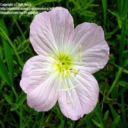

In [1]:
import torchvision
import torch
from PIL import Image

# Define image size 
size = (128, 128)

# Preprocess images: resize and convert to Tensor
transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize(size),  # Resize to 128x128
    torchvision.transforms.ToTensor(),    # Convert to Tensor and scale pixels to [0, 1]
])

# Load training and testing datasets
train_dataset = list(torchvision.datasets.Flowers102(
    "../Introduction/flowers", "train", transform=transform, download=False
))

test_dataset = list(torchvision.datasets.Flowers102(
    "../Introduction/flowers", "test", transform=transform, download=False
))


# Convert a PyTorch Tensor into a PIL Image for visualization
def visualize_image(img: torch.Tensor) -> Image.Image:
    img = img.permute(1, 2, 0)  # Convert CHW to HWC
    img = (img * 255).to(torch.uint8)  # Scale pixels to [0, 255]
    return Image.fromarray(img.numpy())  # Convert to PIL Image


# Visualize the first training image
visualize_image(train_dataset[1][0])  # [0] selects the image, [1] is the label

In [2]:
train_dataset.__len__()

1020

In [3]:
train_dataset.__getitem__(0)

(tensor([[[0.0471, 0.0706, 0.0745,  ..., 0.1255, 0.4667, 0.5647],
          [0.0667, 0.0667, 0.0549,  ..., 0.1333, 0.4824, 0.5647],
          [0.0824, 0.0745, 0.0549,  ..., 0.1451, 0.5059, 0.5686],
          ...,
          [0.1059, 0.1059, 0.0863,  ..., 0.5020, 0.4902, 0.4706],
          [0.1137, 0.1137, 0.1294,  ..., 0.5059, 0.4784, 0.4706],
          [0.1020, 0.1176, 0.1176,  ..., 0.5020, 0.4745, 0.4667]],
 
         [[0.0863, 0.1255, 0.1373,  ..., 0.1294, 0.3412, 0.3961],
          [0.0941, 0.1098, 0.1059,  ..., 0.1294, 0.3490, 0.3922],
          [0.0941, 0.0941, 0.0824,  ..., 0.1294, 0.3608, 0.3843],
          ...,
          [0.2000, 0.1804, 0.1333,  ..., 0.4235, 0.4118, 0.3922],
          [0.2118, 0.2039, 0.2000,  ..., 0.4275, 0.4039, 0.3922],
          [0.2078, 0.2196, 0.2196,  ..., 0.4196, 0.4078, 0.3765]],
 
         [[0.0314, 0.0392, 0.0353,  ..., 0.0863, 0.4745, 0.5961],
          [0.0392, 0.0353, 0.0235,  ..., 0.0980, 0.4902, 0.5922],
          [0.0431, 0.0353, 0.0235,  ...,

In [4]:
len(train_dataset)

1020

In [5]:
help(torch.utils.data.DataLoader)

Help on class DataLoader in module torch.utils.data.dataloader:

class DataLoader(typing.Generic)
 |  DataLoader(
 |      dataset: 'Dataset[_T_co]',
 |      batch_size: 'int | None' = 1,
 |      shuffle: 'bool | None' = None,
 |      sampler: 'Sampler | Iterable | None' = None,
 |      batch_sampler: 'Sampler[list] | Iterable[list] | None' = None,
 |      num_workers: 'int' = 0,
 |      collate_fn: '_collate_fn_t | None' = None,
 |      pin_memory: 'bool' = False,
 |      drop_last: 'bool' = False,
 |      timeout: 'float' = 0,
 |      worker_init_fn: '_worker_init_fn_t | None' = None,
 |      multiprocessing_context=None,
 |      generator=None,
 |      *,
 |      prefetch_factor: 'int | None' = None,
 |      persistent_workers: 'bool' = False,
 |      pin_memory_device: 'str' = '',
 |      in_order: 'bool' = True
 |  ) -> 'None'
 |
 |  Data loader combines a dataset and a sampler, and provides an iterable over the given dataset.
 |
 |  The :class:`~torch.utils.data.DataLoader` suppor

In [6]:
train_loader =  torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
for batch in train_loader:
    print(batch)
    break

[tensor([[[[0.3686, 0.3137, 0.2941,  ..., 0.4667, 0.4706, 0.4588],
          [0.4118, 0.3020, 0.3098,  ..., 0.4824, 0.4745, 0.4588],
          [0.4431, 0.2549, 0.2549,  ..., 0.4980, 0.4784, 0.4667],
          ...,
          [0.1176, 0.1176, 0.1294,  ..., 0.0902, 0.0902, 0.0863],
          [0.1216, 0.1255, 0.1412,  ..., 0.0902, 0.0941, 0.0902],
          [0.1294, 0.1412, 0.1569,  ..., 0.0863, 0.0902, 0.0902]],

         [[0.3451, 0.2941, 0.2627,  ..., 0.5961, 0.6039, 0.5922],
          [0.3843, 0.2667, 0.2784,  ..., 0.6039, 0.6000, 0.5843],
          [0.4039, 0.2078, 0.2118,  ..., 0.6078, 0.6000, 0.5804],
          ...,
          [0.2353, 0.2471, 0.2706,  ..., 0.1333, 0.1255, 0.1176],
          [0.2431, 0.2627, 0.2863,  ..., 0.1373, 0.1333, 0.1216],
          [0.2510, 0.2667, 0.2863,  ..., 0.1373, 0.1294, 0.1216]],

         [[0.3765, 0.3216, 0.3412,  ..., 0.2510, 0.2667, 0.2667],
          [0.4157, 0.3451, 0.3451,  ..., 0.2667, 0.2706, 0.2706],
          [0.4588, 0.3020, 0.2784,  ..., 

In [7]:
train_loader =  torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
for imgs, labels in train_loader:
    print(imgs.shape, labels.shape)
    break

torch.Size([64, 3, 128, 128]) torch.Size([64])


In [ ]:
from typing import Any
import torch

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)


# 1. Model
class MyModel(torch.nn.Module):
    def __init__(self, layer_size=[512, 512, 512]) -> None:
        super().__init__()
        layers = []
        layers.append(torch.nn.Flatten())
        c = 128 * 128 * 3
        for s in layer_size:
            layers.append(torch.nn.Linear(c, s))
            layers.append(torch.nn.ReLU())
            c = s
        layers.append(torch.nn.Linear(c, 102))
        self.model = torch.nn.Sequential(*layers)

    def forward(self, x) -> Any:
        return self.model(x)


model = MyModel()
model.cuda()
# 2. Loss function (nhận raw logits và tự xử lý Softmax + NLL bên trong)
loss_fn = torch.nn.CrossEntropyLoss()

# 3. Optimizer
optim = torch.optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

# 4. Training loop (1 epoch)
model.train()
for imgs, labels in train_loader:
    imgs, labels = imgs.cuda(), labels.cuda()
    imgs = imgs.float()
    labels = labels.long()

    pred = model(imgs)
    loss_val = loss_fn(pred, labels)

    optim.zero_grad()
    loss_val.backward()
    optim.step()

    print(loss_val.item())

4.627873420715332
4.623875141143799
4.624425888061523
4.626430988311768
4.627007007598877
4.630436897277832
4.6197190284729
4.625169277191162
4.629127025604248
4.625984191894531
4.630279541015625
4.621353626251221
4.625453948974609
4.625827789306641
4.615797519683838
4.61954927444458
